# Taller práctico: Análisis de datos académicos con Python

**Pandas · NumPy · Matplotlib | SENA ADSO**

**Nombre del aprendiz:** ______________________________  
**Ficha / grupo:** __________________  **Fecha:** __________________

## Propósito
Analizar el archivo `data (1).csv` para explorar la información académica, calcular estadísticas, comparar resultados, revisar matrícula y becas, construir visualizaciones y redactar un miniinforme con hallazgos y recomendaciones.

> Este cuaderno sigue los siete ejercicios de la guía entregada. Está organizado para ejecutarse en Visual Studio Code con la extensión Jupyter. El archivo CSV se descargará automáticamente desde la fuente UCI si no está disponible o si está vacío.

## Antes de comenzar

Ejecuta las celdas en orden, de arriba hacia abajo. No cambies los nombres originales de las columnas. La lectura utiliza `sep=";"`, tal como indica la guía.

Si la descarga automática no funciona por falta de conexión, el cuaderno mostrará el enlace oficial para descargar el dataset y colocarlo en esta misma carpeta.

In [9]:
# CELDA INICIAL: BIBLIOTECAS Y CARGA DEL DATASET

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from urllib.request import Request, urlopen
from zipfile import ZipFile
from io import BytesIO
import shutil

# Carpetas del proyecto
BASE = Path.cwd()
CARPETA_GRAFICOS = BASE / "graficos"
CARPETA_INFORMES = BASE / "informes"
CARPETA_GRAFICOS.mkdir(exist_ok=True)
CARPETA_INFORMES.mkdir(exist_ok=True)

# Archivo solicitado en la guía
archivo = BASE / "data (1).csv"

# Fuente oficial UCI: dataset 697
URL_UCI = "https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip"

# Si el archivo no existe o está vacío, descargar el original
if not archivo.exists() or archivo.stat().st_size == 0:
    print("No se encontró un CSV válido. Descargando el dataset original de UCI...")
    solicitud = Request(URL_UCI, headers={"User-Agent": "Mozilla/5.0"})
    try:
        with urlopen(solicitud, timeout=60) as respuesta:
            contenido_zip = respuesta.read()

        with ZipFile(BytesIO(contenido_zip)) as paquete:
            nombres = paquete.namelist()
            csv_encontrado = next(
                (nombre for nombre in nombres if nombre.lower().endswith("data.csv")),
                None
            )
            if csv_encontrado is None:
                raise FileNotFoundError("El ZIP descargado no contiene data.csv")
            with paquete.open(csv_encontrado) as origen, open(archivo, "wb") as destino:
                shutil.copyfileobj(origen, destino)
        print("Dataset descargado y guardado como:", archivo.name)
    except Exception as error:
        raise RuntimeError(
            "No fue posible descargar el dataset automáticamente. "
            "Descarga el archivo desde https://archive.ics.uci.edu/dataset/697/ "
            "y coloca data.csv en la carpeta del proyecto con el nombre data (1).csv. "
            f"Detalle: {error}"
        )
else:
    print("Se encontró el archivo local:", archivo.name)

# Leer el CSV con separador punto y coma
df = pd.read_csv(archivo, sep=";")
df.columns = df.columns.str.strip()

print("\nARCHIVO CARGADO CORRECTAMENTE")
print("Dimensiones:", df.shape)
print("Registros:", len(df))
print("Variables:", len(df.columns))

# Validaciones para detectar archivos equivocados o mal leídos
if df.shape != (4424, 37):
    raise ValueError(
        f"Se esperaba (4424, 37), pero se obtuvo {df.shape}. "
        "Verifica que sea el CSV original y que se use sep=';'."
    )
if "Target" not in df.columns:
    raise ValueError("No aparece la columna Target. Revisa el archivo CSV.")

display(df.head())


Se encontró el archivo local: data (1).csv

ARCHIVO CARGADO CORRECTAMENTE
Dimensiones: (4424, 37)
Registros: 4424
Variables: 37


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


# Ejercicio 1. Lectura y exploración general del archivo

**Objetivo:** reconocer la estructura del conjunto de datos y revisar la calidad básica de la información.

Se mostrarán las primeras 10 filas, las últimas 5, dimensiones, tipos de datos, valores nulos y estadísticas descriptivas.

In [10]:
# EJERCICIO 1: LECTURA Y EXPLORACIÓN GENERAL

# 1. Primeras 10 filas y últimas 5 filas
print("PRIMERAS 10 FILAS")
display(df.head(10))

print("ÚLTIMAS 5 FILAS")
display(df.tail(5))

# 2. Dimensiones del DataFrame
filas, columnas = df.shape
print("Cantidad de estudiantes:", filas)
print("Cantidad de variables:", columnas)

# 3. Nombres y tipos de datos
print("\nINFORMACIÓN DE LAS COLUMNAS")
df.info()

# 4. Valores nulos por columna
print("\nVALORES NULOS POR COLUMNA")
nulos = df.isnull().sum()
display(nulos.to_frame(name="Valores nulos"))
print("Total de celdas nulas:", int(nulos.sum()))

# 5. Estadísticas descriptivas de las variables numéricas
print("\nESTADÍSTICAS DESCRIPTIVAS")
display(df.describe().round(2))


PRIMERAS 10 FILAS


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate
5,2,39,1,9991,0,19,133.1,1,37,37,...,0,5,17,5,11.500000,5,16.2,0.3,-0.92,Graduate
6,1,1,1,9500,1,1,142.0,1,19,38,...,0,8,8,8,14.345000,0,15.5,2.8,-4.06,Graduate
7,1,18,4,9254,1,1,119.0,1,37,37,...,0,5,5,0,0.000000,0,15.5,2.8,-4.06,Dropout
8,1,1,3,9238,1,1,137.0,62,1,1,...,0,6,7,6,14.142857,0,16.2,0.3,-0.92,Graduate
9,1,1,1,9238,1,1,138.0,1,1,19,...,0,6,14,2,13.500000,0,8.9,1.4,3.51,Dropout


ÚLTIMAS 5 FILAS


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
4419,1,1,6,9773,1,1,125.0,1,1,1,...,0,6,8,5,12.666667,0,15.5,2.8,-4.06,Graduate
4420,1,1,2,9773,1,1,120.0,105,1,1,...,0,6,6,2,11.000000,0,11.1,0.6,2.02,Dropout
4421,1,1,1,9500,1,1,154.0,1,37,37,...,0,8,9,1,13.500000,0,13.9,-0.3,0.79,Dropout
4422,1,1,1,9147,1,1,180.0,1,37,37,...,0,5,6,5,12.000000,0,9.4,-0.8,-3.12,Graduate
4423,1,10,1,9773,1,1,152.0,22,38,37,...,0,6,6,6,13.000000,0,12.7,3.7,-1.70,Graduate


Cantidad de estudiantes: 4424
Cantidad de variables: 37

INFORMACIÓN DE LAS COLUMNAS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification           

,Valores nulos
Marital status,0
Application mode,0
Application order,0
Course,0
Daytime/evening attendance,0
Previous qualification,0
Previous qualification (grade),0
Nacionality,0
Mother's qualification,0
Father's qualification,0


Total de celdas nulas: 0

ESTADÍSTICAS DESCRIPTIVAS


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,...,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00
mean,1.18,18.67,1.73,8856.64,0.89,4.58,132.61,1.87,19.56,22.28,...,0.14,0.54,6.23,8.06,4.44,10.23,0.15,11.57,1.23,0.00
std,0.61,17.48,1.31,2063.57,0.31,10.22,13.19,6.91,15.60,15.34,...,0.69,1.92,2.20,3.95,3.01,5.21,0.75,2.66,1.38,2.27
min,1.00,1.00,0.00,33.00,0.00,1.00,95.00,1.00,1.00,1.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,7.60,-0.80,-4.06
25%,1.00,1.00,1.00,9085.00,1.00,1.00,125.00,1.00,2.00,3.00,...,0.00,0.00,5.00,6.00,2.00,10.75,0.00,9.40,0.30,-1.70
50%,1.00,17.00,1.00,9238.00,1.00,1.00,133.10,1.00,19.00,19.00,...,0.00,0.00,6.00,8.00,5.00,12.20,0.00,11.10,1.40,0.32
75%,1.00,39.00,2.00,9556.00,1.00,1.00,140.00,1.00,37.00,37.00,...,0.00,0.00,7.00,10.00,6.00,13.33,0.00,13.90,2.60,1.79
max,6.00,57.00,9.00,9991.00,1.00,43.00,190.00,109.00,44.00,44.00,...,12.00,19.00,23.00,33.00,20.00,18.57,12.00,16.20,3.70,3.51


### Preguntas de análisis — Ejercicio 1

- **¿Cuántos estudiantes y variables contiene el archivo?** 4.424 estudiantes y 37 variables.
- **¿Qué diferencia existe entre una variable numérica y una variable de texto?** Una variable numérica almacena cantidades o códigos representados con números y permite operaciones matemáticas cuando su significado lo permite. Una variable de texto almacena etiquetas o categorías, como `Target`.
- **¿Se observan valores nulos? ¿Qué decisión tomaría si existieran?** La celda anterior muestra el conteo real por columna. Si hubiera nulos, primero revisaría su cantidad y significado; no los reemplazaría sin justificar la decisión.

# Ejercicio 2. Estadística descriptiva con NumPy

**Objetivo:** calcular medidas estadísticas sobre la edad y la calificación de admisión mediante arreglos NumPy.

In [11]:
# EJERCICIO 2: ESTADÍSTICA DESCRIPTIVA CON NUMPY

# Convertir columnas de Pandas en arreglos NumPy
edades = df["Age at enrollment"].to_numpy()
notas_admision = df["Admission grade"].to_numpy()

# Estadísticas de edad
print("ESTADÍSTICAS DE EDAD")
print("Promedio:", round(np.mean(edades), 2))
print("Mediana:", round(float(np.median(edades)), 2))
print("Mínimo:", np.min(edades))
print("Máximo:", np.max(edades))
print("Desviación estándar:", round(float(np.std(edades)), 2))

# Conteos mediante filtros booleanos de NumPy
print("Mayores de 25 años:", int(np.sum(edades > 25)))
print("Menores de 20 años:", int(np.sum(edades < 20)))

# Estadísticas de calificación de admisión
print("\nCALIFICACIÓN DE ADMISIÓN")
print("Promedio:", round(float(np.mean(notas_admision)), 2))
print("Desviación estándar:", round(float(np.std(notas_admision)), 2))
print("Mínimo:", np.min(notas_admision))
print("Máximo:", np.max(notas_admision))


ESTADÍSTICAS DE EDAD
Promedio: 23.27
Mediana: 20.0
Mínimo: 17
Máximo: 70
Desviación estándar: 7.59
Mayores de 25 años: 1045
Menores de 20 años: 1952

CALIFICACIÓN DE ADMISIÓN
Promedio: 126.98
Desviación estándar: 14.48
Mínimo: 95.0
Máximo: 190.0


### Preguntas de análisis — Ejercicio 2

- **¿Qué representa la mediana de edad?** Es el valor central al ordenar las edades; la mitad de los registros queda por debajo y la otra mitad por encima o igual.
- **¿Por qué el promedio puede ser diferente de la mediana?** Porque el promedio considera todos los valores y puede cambiar por edades muy altas o muy bajas; la mediana depende de la posición central.
- **¿Qué información aporta la desviación estándar?** Indica qué tan dispersos están los datos respecto al promedio.

# Ejercicio 3. Distribución de los resultados académicos

**Objetivo:** contar las categorías de `Target`, calcular sus porcentajes, obtener la edad promedio de cada grupo e identificar el grupo con mayor edad promedio.

In [12]:
# EJERCICIO 3: DISTRIBUCIÓN DE LOS RESULTADOS ACADÉMICOS

# Conteo por categoría
conteo = df["Target"].value_counts()
print("CANTIDAD DE ESTUDIANTES POR RESULTADO")
display(conteo.to_frame(name="Cantidad"))

# Porcentajes calculados con NumPy
total = len(df)
porcentajes = (conteo.to_numpy() / total) * 100

# DataFrame de resumen (Series alineadas por índice)
resumen_resultados = pd.DataFrame({
    "Cantidad": conteo,
    "Porcentaje": (conteo / total) * 100
})
print("\nCANTIDAD Y PORCENTAJE POR RESULTADO")
display(resumen_resultados.round(2))

# Edad promedio por resultado
edad_por_resultado = df.groupby("Target")["Age at enrollment"].mean()
print("\nEDAD PROMEDIO POR RESULTADO")
display(edad_por_resultado.round(2).to_frame(name="Edad promedio"))

print("Grupo con mayor edad promedio:", edad_por_resultado.idxmax())


CANTIDAD DE ESTUDIANTES POR RESULTADO


,Cantidad
Target,
Graduate,2209
Dropout,1421
Enrolled,794



CANTIDAD Y PORCENTAJE POR RESULTADO


,Cantidad,Porcentaje
Target,,
Graduate,2209,49.93
Dropout,1421,32.12
Enrolled,794,17.95



EDAD PROMEDIO POR RESULTADO


,Edad promedio
Target,
Dropout,26.07
Enrolled,22.37
Graduate,21.78


Grupo con mayor edad promedio: Dropout


### Preguntas de análisis — Ejercicio 3

- **¿Cuál es el resultado con mayor cantidad de estudiantes?** Se identifica en la primera fila de `resumen_resultados`, ordenada de mayor a menor frecuencia.
- **¿Qué porcentaje corresponde a Dropout?** Se consulta en la fila `Dropout` de la columna `Porcentaje`.
- **¿Qué diferencias se observan en la edad promedio?** Se comparan los promedios de `Graduate`, `Dropout` y `Enrolled` mostrados en la tabla. Las diferencias describen los grupos, pero no explican por sí solas las causas del resultado.

# Ejercicio 4. Comparación del rendimiento académico por semestre

**Objetivo:** comparar las calificaciones y las asignaturas aprobadas en el primer y segundo semestre, por resultado académico.

In [13]:
# EJERCICIO 4: COMPARACIÓN DEL RENDIMIENTO POR SEMESTRE

col_nota_1 = "Curricular units 1st sem (grade)"
col_nota_2 = "Curricular units 2nd sem (grade)"
col_aprobadas_1 = "Curricular units 1st sem (approved)"
col_aprobadas_2 = "Curricular units 2nd sem (approved)"

# Convertir las notas en arreglos NumPy
nota_1 = df[col_nota_1].to_numpy()
nota_2 = df[col_nota_2].to_numpy()

print("Promedio general primer semestre:", round(float(np.mean(nota_1)), 2))
print("Promedio general segundo semestre:", round(float(np.mean(nota_2)), 2))

# Promedios de notas y asignaturas aprobadas por Target
comparacion = df.groupby("Target")[[
    col_nota_1, col_nota_2, col_aprobadas_1, col_aprobadas_2
]].mean()

print("\nPROMEDIOS POR RESULTADO ACADÉMICO")
display(comparacion.round(2))

# Diferencia individual entre las notas de ambos semestres
df["Diferencia_notas"] = df[col_nota_2] - df[col_nota_1]
diferencias = df["Diferencia_notas"].to_numpy()

print("\nCAMBIO DE CALIFICACIÓN ENTRE SEMESTRES")
print("Mejoraron:", int(np.sum(diferencias > 0)))
print("Disminuyeron:", int(np.sum(diferencias < 0)))
print("Mantuvieron:", int(np.sum(diferencias == 0)))


Promedio general primer semestre: 10.64
Promedio general segundo semestre: 10.23

PROMEDIOS POR RESULTADO ACADÉMICO


,Curricular units 1st sem (grade),Curricular units 2nd sem (grade),Curricular units 1st sem (approved),Curricular units 2nd sem (approved)
Target,,,,
Dropout,7.26,5.90,2.55,1.94
Enrolled,11.13,11.12,4.32,4.06
Graduate,12.64,12.70,6.23,6.18



CAMBIO DE CALIFICACIÓN ENTRE SEMESTRES
Mejoraron: 1554
Disminuyeron: 1721
Mantuvieron: 1149


### Preguntas de análisis — Ejercicio 4

- **¿Qué grupo tiene el mayor promedio de calificaciones?** Se identifica comparando las columnas de notas de la tabla `comparacion`.
- **¿El promedio del segundo semestre es mayor o menor que el primero?** Se comparan los dos promedios generales impresos arriba.
- **¿Qué limitaciones tiene comparar únicamente promedios?** El promedio puede ocultar diferencias internas, valores extremos y tamaños distintos de los grupos. Por eso se debe acompañar con conteos y otras medidas.

# Ejercicio 5. Estado de matrícula y becas

**Objetivo:** analizar el estado de pago de matrícula y la condición de becario frente al resultado académico. Las tablas cruzadas muestran frecuencias y asociaciones; no demuestran causalidad.

In [14]:
# EJERCICIO 5: ESTADO DE MATRÍCULA Y BECAS

# Convertir las columnas a arreglos NumPy
matricula = df["Tuition fees up to date"].to_numpy()
beca = df["Scholarship holder"].to_numpy()

# Estado de pago
al_dia = int(np.sum(matricula == 1))
pendiente = int(np.sum(matricula == 0))

print("MATRÍCULA")
print("Matrícula al día:", al_dia)
print("Matrícula pendiente:", pendiente)
print("Porcentaje al día:", round(al_dia / len(df) * 100, 2), "%")
print("Porcentaje pendiente:", round(pendiente / len(df) * 100, 2), "%")

# Becas
con_beca = int(np.sum(beca == 1))
sin_beca = int(np.sum(beca == 0))
print("\nBECAS")
print("Estudiantes con beca:", con_beca)
print("Estudiantes sin beca:", sin_beca)
print("Porcentaje con beca:", round(con_beca / len(df) * 100, 2), "%")
print("Porcentaje sin beca:", round(sin_beca / len(df) * 100, 2), "%")

# Tablas cruzadas
print("\nMATRÍCULA FRENTE A RESULTADO ACADÉMICO")
tabla_matricula_target = pd.crosstab(df["Tuition fees up to date"], df["Target"])
display(tabla_matricula_target)

print("\nBECA FRENTE A RESULTADO ACADÉMICO")
tabla_beca_target = pd.crosstab(df["Scholarship holder"], df["Target"])
display(tabla_beca_target)


MATRÍCULA
Matrícula al día: 3896
Matrícula pendiente: 528
Porcentaje al día: 88.07 %
Porcentaje pendiente: 11.93 %

BECAS
Estudiantes con beca: 1099
Estudiantes sin beca: 3325
Porcentaje con beca: 24.84 %
Porcentaje sin beca: 75.16 %

MATRÍCULA FRENTE A RESULTADO ACADÉMICO


Target,Dropout,Enrolled,Graduate
Tuition fees up to date,,,
0,457,42,29
1,964,752,2180



BECA FRENTE A RESULTADO ACADÉMICO


Target,Dropout,Enrolled,Graduate
Scholarship holder,,,
0,1287,664,1374
1,134,130,835


### Preguntas de análisis — Ejercicio 5

- **¿Cuántos estudiantes tienen matrícula pendiente?** Consulta el indicador `pendiente`.
- **¿Qué resultado aparece con mayor frecuencia entre quienes tienen matrícula pendiente?** Revisa la fila `0` de `tabla_matricula_target`.
- **¿Qué diferencias se observan entre estudiantes con beca y sin beca?** Compara las filas `1` y `0` de `tabla_beca_target`. Recuerda que una tabla cruzada muestra asociación, no prueba que la beca o el pago causen un resultado.

# Ejercicio 6. Visualización de datos con Matplotlib

Se construirán los cuatro gráficos solicitados: barras por `Target`, histograma de edades, barras agrupadas de promedios semestrales y dispersión entre notas de ambos semestres. Los gráficos se mostrarán y se guardarán en la carpeta `graficos`.

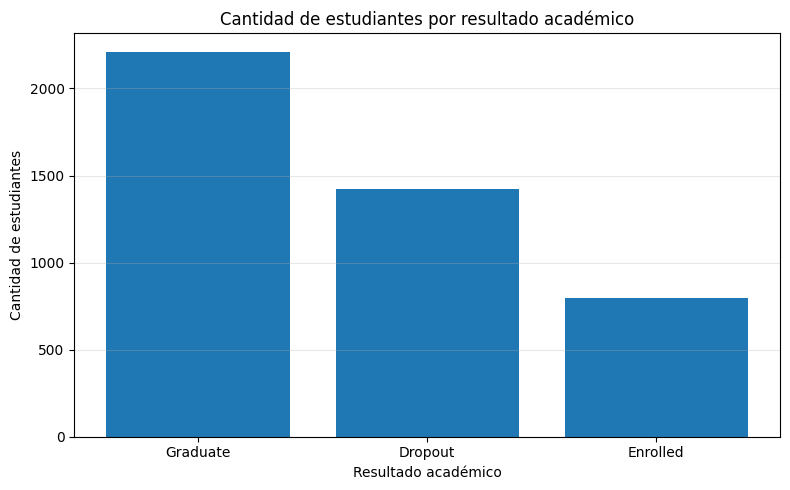

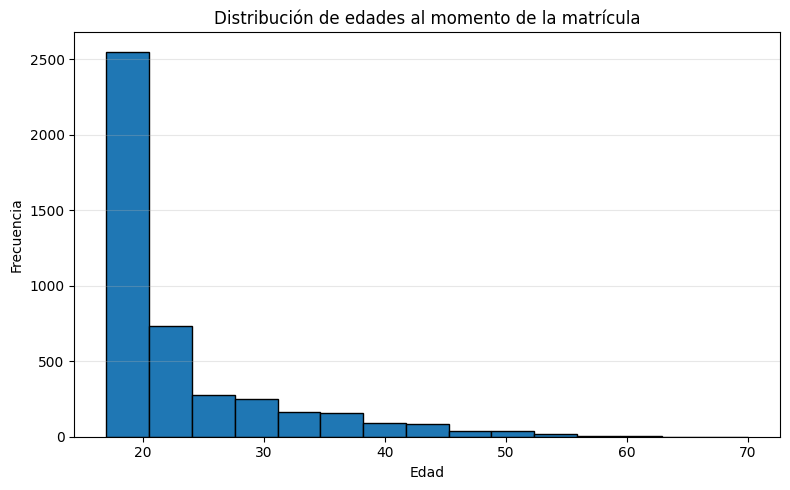

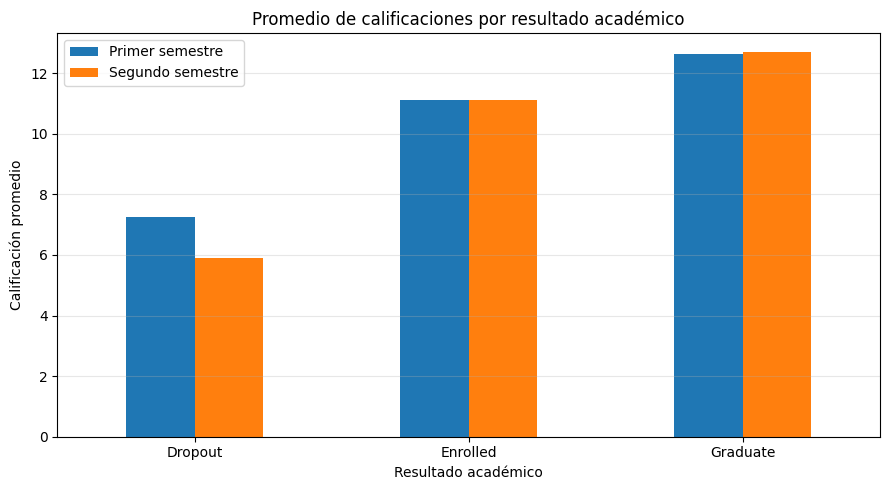

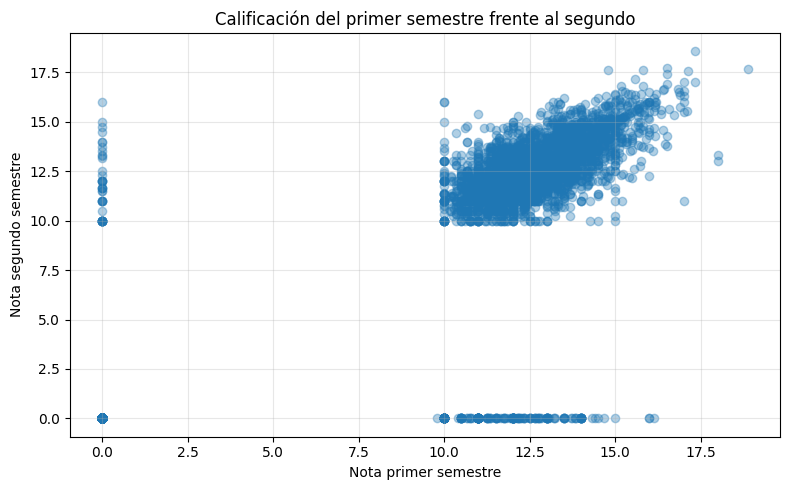

Los cuatro gráficos se guardaron en: C:\Users\ASUS\Downloads\Taller_Analisis_Academico_COMPLETO_VSCode\Taller_Analisis_Academico_COMPLETO_VSCode\graficos


In [15]:
# EJERCICIO 6: VISUALIZACIÓN CON MATPLOTLIB

# Gráfico 1: cantidad de estudiantes por resultado
conteo_grafico = df["Target"].value_counts()
plt.figure(figsize=(8, 5))
plt.bar(conteo_grafico.index, conteo_grafico.values)
plt.title("Cantidad de estudiantes por resultado académico")
plt.xlabel("Resultado académico")
plt.ylabel("Cantidad de estudiantes")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(CARPETA_GRAFICOS / "01_estudiantes_por_resultado.png", dpi=160, bbox_inches="tight")
plt.show()

# Gráfico 2: distribución de edades
plt.figure(figsize=(8, 5))
plt.hist(df["Age at enrollment"], bins=15, edgecolor="black")
plt.title("Distribución de edades al momento de la matrícula")
plt.xlabel("Edad")
plt.ylabel("Frecuencia")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(CARPETA_GRAFICOS / "02_distribucion_edades.png", dpi=160, bbox_inches="tight")
plt.show()

# Gráfico 3: promedio de notas por resultado y semestre
promedios = df.groupby("Target")[[col_nota_1, col_nota_2]].mean()
ax = promedios.plot(kind="bar", figsize=(9, 5))
ax.set_title("Promedio de calificaciones por resultado académico")
ax.set_xlabel("Resultado académico")
ax.set_ylabel("Calificación promedio")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(["Primer semestre", "Segundo semestre"])
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(CARPETA_GRAFICOS / "03_promedio_notas_por_resultado.png", dpi=160, bbox_inches="tight")
plt.show()

# Gráfico 4: relación entre calificaciones de los dos semestres
plt.figure(figsize=(8, 5))
plt.scatter(df[col_nota_1], df[col_nota_2], alpha=0.35)
plt.title("Calificación del primer semestre frente al segundo")
plt.xlabel("Nota primer semestre")
plt.ylabel("Nota segundo semestre")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(CARPETA_GRAFICOS / "04_dispersion_notas_semestres.png", dpi=160, bbox_inches="tight")
plt.show()

print("Los cuatro gráficos se guardaron en:", CARPETA_GRAFICOS.resolve())


### Preguntas de análisis — Ejercicio 6

- **¿Qué categoría tiene la barra más alta?** Se identifica en el gráfico de cantidad por `Target`.
- **¿En qué rango de edades se concentra una mayor cantidad?** Se observa en la barra más alta del histograma.
- **¿Qué patrón se observa en la dispersión?** Una tendencia ascendente indica que quienes obtienen notas más altas en el primer semestre suelen mostrar notas más altas en el segundo; el grado de asociación se cuantifica en el ejercicio 7.
- **¿Cuál gráfico comunica mejor un hallazgo?** Una respuesta válida es el gráfico de barras por `Target`, porque permite comparar directamente el tamaño de los tres grupos.

# Ejercicio 7. Miniinforme: factores asociados al resultado académico

Se seleccionarán edad, calificación de admisión, calificaciones y asignaturas aprobadas de ambos semestres. Se calculará la matriz de correlación, la correlación específica con NumPy, un mapa de calor y un resumen por `Target`. Al final se generará automáticamente un miniinforme con cinco hallazgos y dos recomendaciones.

MATRIZ DE CORRELACIÓN


,Age at enrollment,Admission grade,Curricular units 1st sem (grade),Curricular units 1st sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (approved)
Age at enrollment,1.00,-0.03,-0.16,-0.05,-0.17,-0.11
Admission grade,-0.03,1.00,0.07,0.07,0.07,0.08
Curricular units 1st sem (grade),-0.16,0.07,1.00,0.70,0.84,0.67
Curricular units 1st sem (approved),-0.05,0.07,0.70,1.00,0.69,0.90
Curricular units 2nd sem (grade),-0.17,0.07,0.84,0.69,1.00,0.76
Curricular units 2nd sem (approved),-0.11,0.08,0.67,0.90,0.76,1.00


Correlación entre notas de ambos semestres: 0.8372


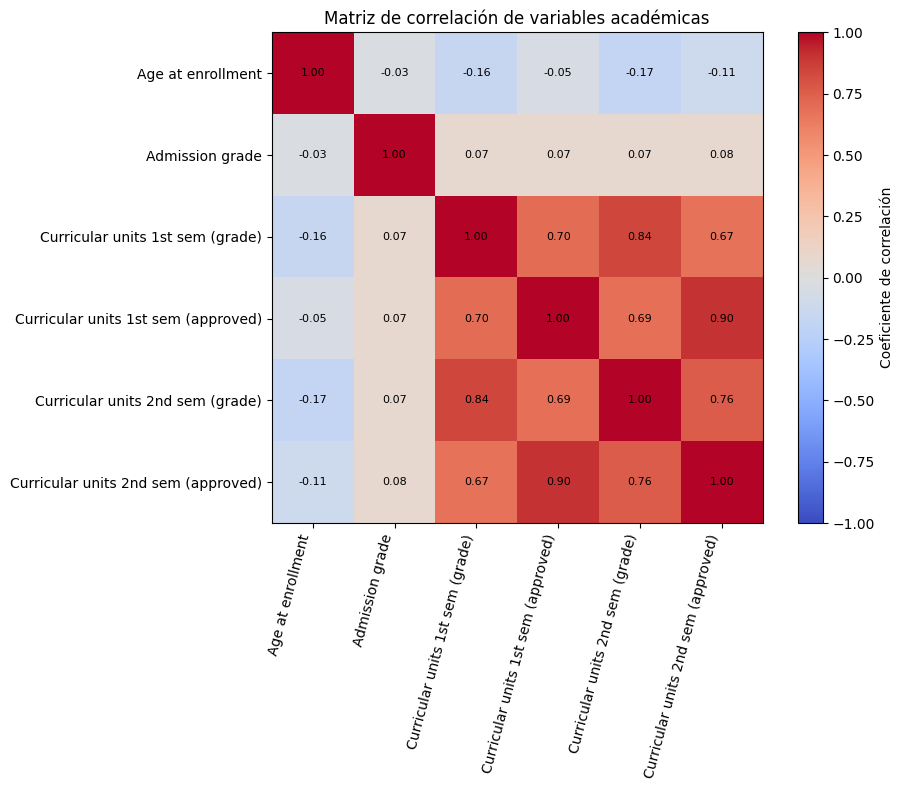

RESUMEN POR RESULTADO ACADÉMICO


,estudiantes,edad_promedio,nota_semestre_1,nota_semestre_2,aprobadas_semestre_1,aprobadas_semestre_2
Target,,,,,,
Dropout,1421,26.07,7.26,5.90,2.55,1.94
Enrolled,794,22.37,11.13,11.12,4.32,4.06
Graduate,2209,21.78,12.64,12.70,6.23,6.18



CINCO HALLAZGOS
1. El resultado más frecuente es Graduate, con 2209 estudiantes (49.93%).
2. Dropout representa 32.12% del total de estudiantes.
3. El grupo con mayor edad promedio es Dropout, con 26.07 años.
4. El promedio de nota del primer semestre es 10.64 y el del segundo semestre es 10.23.
5. La correlación entre las notas del primer y segundo semestre es 0.8372; indica asociación lineal, no causalidad.

DOS RECOMENDACIONES
1. Revisar periódicamente las notas y las asignaturas aprobadas de ambos semestres para identificar grupos que puedan necesitar acompañamiento académico.
2. Ampliar el análisis con información de nuevas cohortes y variables institucionales antes de tomar decisiones o atribuir causas a la deserción.

Miniinforme guardado en: C:\Users\ASUS\Downloads\Taller_Analisis_Academico_COMPLETO_VSCode\Taller_Analisis_Academico_COMPLETO_VSCode\informes\Miniinforme_Analisis_Academico.md


In [16]:
# EJERCICIO 7: MATRIZ DE CORRELACIÓN Y MINIINFORME

variables = [
    "Age at enrollment",
    "Admission grade",
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (approved)",
    "Curricular units 2nd sem (grade)",
    "Curricular units 2nd sem (approved)"
]

# Matriz de correlación con Pandas
matriz_corr = df[variables].corr()
print("MATRIZ DE CORRELACIÓN")
display(matriz_corr.round(2))

# Correlación entre notas de ambos semestres con NumPy
nota_1 = df[col_nota_1].to_numpy()
nota_2 = df[col_nota_2].to_numpy()
corr_numpy = np.corrcoef(nota_1, nota_2)[0, 1]
print("Correlación entre notas de ambos semestres:", round(float(corr_numpy), 4))

# Mapa de calor de la matriz de correlación
plt.figure(figsize=(10, 8))
plt.imshow(matriz_corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Coeficiente de correlación")
plt.xticks(range(len(variables)), variables, rotation=75, ha="right")
plt.yticks(range(len(variables)), variables)

for i in range(len(variables)):
    for j in range(len(variables)):
        plt.text(j, i, f"{matriz_corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

plt.title("Matriz de correlación de variables académicas")
plt.tight_layout()
plt.savefig(CARPETA_GRAFICOS / "05_matriz_correlacion.png", dpi=160, bbox_inches="tight")
plt.show()

# Resumen por resultado académico
resumen_final = df.groupby("Target").agg(
    estudiantes=("Target", "size"),
    edad_promedio=("Age at enrollment", "mean"),
    nota_semestre_1=(col_nota_1, "mean"),
    nota_semestre_2=(col_nota_2, "mean"),
    aprobadas_semestre_1=(col_aprobadas_1, "mean"),
    aprobadas_semestre_2=(col_aprobadas_2, "mean")
)

print("RESUMEN POR RESULTADO ACADÉMICO")
display(resumen_final.round(2))

# Cinco hallazgos calculados a partir de los datos reales
conteo_target = df["Target"].value_counts()
porcentaje_target = df["Target"].value_counts(normalize=True) * 100
edad_media_target = df.groupby("Target")["Age at enrollment"].mean()

mayor_grupo = conteo_target.idxmax()
mayor_edad_grupo = edad_media_target.idxmax()
mayor_edad_valor = edad_media_target.max()
media_nota_1 = np.mean(nota_1)
media_nota_2 = np.mean(nota_2)

hallazgos = [
    f"El resultado más frecuente es {mayor_grupo}, con {int(conteo_target.loc[mayor_grupo])} estudiantes ({porcentaje_target.loc[mayor_grupo]:.2f}%).",
    f"Dropout representa {porcentaje_target.get('Dropout', 0):.2f}% del total de estudiantes.",
    f"El grupo con mayor edad promedio es {mayor_edad_grupo}, con {mayor_edad_valor:.2f} años.",
    f"El promedio de nota del primer semestre es {media_nota_1:.2f} y el del segundo semestre es {media_nota_2:.2f}.",
    f"La correlación entre las notas del primer y segundo semestre es {corr_numpy:.4f}; indica asociación lineal, no causalidad."
]

recomendaciones = [
    "Revisar periódicamente las notas y las asignaturas aprobadas de ambos semestres para identificar grupos que puedan necesitar acompañamiento académico.",
    "Ampliar el análisis con información de nuevas cohortes y variables institucionales antes de tomar decisiones o atribuir causas a la deserción."
]

print("\nCINCO HALLAZGOS")
for numero, hallazgo in enumerate(hallazgos, start=1):
    print(f"{numero}. {hallazgo}")

print("\nDOS RECOMENDACIONES")
for numero, recomendacion in enumerate(recomendaciones, start=1):
    print(f"{numero}. {recomendacion}")

# Crear miniinforme Markdown de 1 a 2 páginas
informe = []
informe.append("# Miniinforme: factores asociados al resultado académico\n")
informe.append("## Introducción\n")
informe.append(
    "Se analizó el conjunto de datos académico indicado en la guía, compuesto por "
    f"{len(df):,} registros de estudiantes y {len(df.columns)} variables. "
    "La columna Target identifica tres resultados: Graduate, Dropout y Enrolled. "
    "El trabajo utiliza Pandas para organizar y agrupar la información, NumPy para "
    "los cálculos estadísticos y Matplotlib para las visualizaciones.\n"
)
informe.append("## Indicadores principales por resultado\n")
informe.append(resumen_final.round(2).to_markdown())
informe.append("\n\n## Correlación entre las notas semestrales\n")
informe.append(f"La correlación calculada con NumPy entre las notas del primer y segundo semestre es **{corr_numpy:.4f}**. Esta medida describe asociación lineal y no demuestra causalidad.\n")
informe.append("## Cinco hallazgos\n")
for numero, hallazgo in enumerate(hallazgos, start=1):
    informe.append(f"{numero}. {hallazgo}\n")
informe.append("## Dos recomendaciones\n")
for numero, recomendacion in enumerate(recomendaciones, start=1):
    informe.append(f"{numero}. {recomendacion}\n")
informe.append("## Nota metodológica\n")
informe.append("Los resultados describen únicamente el archivo analizado. Las asociaciones observadas no permiten establecer causas de deserción ni generalizar automáticamente a otras instituciones o cohortes.\n")

ruta_informe = CARPETA_INFORMES / "Miniinforme_Analisis_Academico.md"
ruta_informe.write_text("\n".join(informe), encoding="utf-8")
print("\nMiniinforme guardado en:", ruta_informe.resolve())


# Cierre y comprobaciones finales

La guía indica como entregables el notebook ejecutado, el CSV original, los gráficos de los ejercicios 6 y 7 y el miniinforme del ejercicio 7.

Cuando termines, comprueba que existan estos archivos:

- `data (1).csv`
- `graficos/01_estudiantes_por_resultado.png`
- `graficos/02_distribucion_edades.png`
- `graficos/03_promedio_notas_por_resultado.png`
- `graficos/04_dispersion_notas_semestres.png`
- `graficos/05_matriz_correlacion.png`
- `informes/Miniinforme_Analisis_Academico.md`
- `Taller_Analisis_Academico.ipynb`

**Importante:** guarda el cuaderno después de ejecutar todas las celdas para que las salidas queden visibles al abrirlo.